# IR TrueFISP With a Golden-Ratio-Based Radial Readout: Fast Quantification of T1, T2, and Proton Density

Demo notebook

In [1]:
%matplotlib widget

import sys
from typing import Optional, Tuple

import matplotlib.pyplot as plt
import Modules.ConcatSum
import Modules.Resnet
import MRzeroCore as mr0
import numpy as np
import pypulseq as pp
import torch
import torch.nn as nn
import torchkbnufft as tkbn
from Modules.CoilSens import cyclic_head_coil
from Modules.FourierTransform import (
    nonuniform_fourier_transform_adjoint,
    nonuniform_fourier_transform_forward,
)
from Modules.Linops import ChannelOperator, IdentityOperator, LinearOperator
from Modules.NumSolvers import conjugate_gradient
from Modules.Plan import KbNufft, KbNufftAdjoint
from Modules.Regularizer import Regularizer
from pypulseq import Sequence
from tqdm import tqdm

sys.path.insert(0, "..")
from Modules import default_system, load_brain_phantom

torch.set_default_device("cuda")

/opt/conda/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
# Auxiliary functions

class NonuniformFourierTransformOperator(LinearOperator):

    def __init__(
        self,
        k: torch.Tensor,
        input_shape: Tuple[int, ...],
        device: Optional[torch.device] = None,
    ):
        nD, nK, nTI = k.shape
        nC, nX, nY, TI = input_shape

        self.n_modes = (nX, nY)
        self.k = k
        self.forward_shape = (nC, nX, nY, 1, nTI)
        self.adjoint_shape = (nC, nK, nTI)
        self.shape = (
            int(2 * torch.prod(torch.tensor(self.adjoint_shape))),
            int(2 * torch.prod(torch.tensor(self.forward_shape))),
        )
        self.nufft_ob = KbNufft(im_size=self.n_modes).to(device)
        self.adj_ob = KbNufftAdjoint(im_size=self.n_modes).to(device)

        self.dtype = torch.float32
        self.device = device

    def _matvec(self, x: torch.Tensor) -> torch.Tensor:
        x = torch.view_as_complex(x.reshape(-1, 2)).reshape(self.forward_shape)
        y = nonuniform_fourier_transform_forward(self.k, x, nufft_ob=self.nufft_ob)
        return torch.view_as_real(y.reshape(-1)).reshape(-1)

    def _rmatvec(self, x: torch.Tensor) -> torch.Tensor:
        x = torch.view_as_complex(x.reshape(-1, 2)).reshape(self.adjoint_shape)
        y = nonuniform_fourier_transform_adjoint(
            self.k, x, self.n_modes, adj_ob=self.adj_ob
        )
        return torch.view_as_real(y.reshape(-1)).reshape(-1)

class ChannelOperator(LinearOperator):

    def __init__(
        self,
        coil_sensitivities: torch.Tensor,
        data_shape: Tuple[int, ...],
        device: Optional[torch.device] = None,
    ):
        nC = coil_sensitivities.shape[0]

        self.coil_sensitivities = coil_sensitivities
        self.device = device
        self.dtype = torch.float32
        self.internal_dtype = torch.complex64
        self.forward_shape = (1, *data_shape)
        self.adjoint_shape = (nC, *data_shape)
        self.shape = (
            int(2 * torch.prod(torch.tensor(self.adjoint_shape))),
            int(2 * torch.prod(torch.tensor(self.forward_shape))),
        )

    def _matvec(self, x: torch.Tensor) -> torch.Tensor:
        x = x.view(self.internal_dtype).reshape(self.forward_shape)
        y = self.coil_sensitivities * x
        return y.view(torch.float32).ravel()

    def _rmatvec(self, x: torch.Tensor) -> torch.Tensor:
        x = x.view(self.internal_dtype).reshape(self.adjoint_shape)
        y = torch.sum(torch.conj(self.coil_sensitivities) * x, dim=0, keepdim=True)
        return y.view(torch.float32).ravel()

def conjugate_gradient(
    Q: LinearOperator,
    b: torch.Tensor,
    x: torch.Tensor,
    maxiter: int = 10,
    disable_progressbar: bool = False,
) -> torch.Tensor:

    g_prev = torch.ones(x.shape, dtype=x.dtype)
    p_prev = torch.zeros(x.shape, dtype=x.dtype)

    for iteration in tqdm(range(maxiter), disable=disable_progressbar):

        g = Q @ x - b

        conjugacy_factor = g @ g / (g_prev @ g_prev)
        p = g + conjugacy_factor * p_prev
        stepsize = g @ g / (p @ (Q @ p))
        x = x - stepsize * p

        g_prev = g.clone()
        p_prev = p.clone()

    return x

In [3]:
# Sequence definition

def truefisp_seq(
    FOV: float = 250e-3,
    N_x: int = 64,
    alpha: float = 50.0,
    slice_thickness: float = 5e-3,
    TE: float = 3.98e-3,
    N_readout: int = 700,
    N_spokes: int = 1,
    R=1,
    N_dummy: int = 20,
    TI_start: float = 20e-3,
    TI_inter: float = 0.0,
    TD: float = 2000e-3,
    write_seq: bool = False,
    plot: bool = False,
) -> pp.Sequence:

    system = default_system()
    seq = pp.Sequence(system)
    deltak = 1 / FOV

    rf_inv, gz_inv, _ = pp.make_sinc_pulse(
        flip_angle=np.deg2rad(180),
        duration=10e-3,
        slice_thickness=slice_thickness,
        apodization=0.5,
        time_bw_product=4,
        system=system,
        return_gz=True,
        use="inversion",
    )

    rf, gz, _ = pp.make_sinc_pulse(
        apodization=0.5,
        duration=2e-3,
        flip_angle=np.deg2rad(alpha),
        slice_thickness=slice_thickness,
        system=system,
        time_bw_product=4,
        return_gz=True,
        use="excitation",
    )

    gx_base = pp.make_trapezoid(
        channel="x", flat_area=N_x * deltak, flat_time=6.4e-3 / 5, system=system
    )
    adc = pp.make_adc(
        num_samples=N_x,
        duration=gx_base.flat_time,
        delay=gx_base.rise_time,
        system=system,
    )

    gx_pre_base = pp.make_trapezoid(
        channel="x", area=-gx_base.area / 2, duration=2e-3, system=system
    )
    gz_reph = pp.make_trapezoid(
        channel="z", area=-gz.area / 2, duration=2e-3, system=system
    )

    delay_TE = (
        np.ceil(
            (
                TE
                - pp.calc_duration(gx_pre_base)
                - gz.fall_time
                - gz.flat_time / 2
                - pp.calc_duration(gx_base) / 2
            )
            / seq.grad_raster_time
        )
        * seq.grad_raster_time
    )
    inv_duration = pp.calc_duration(rf_inv, gz_inv)
    delay_TI_start = (
        np.ceil(
            (TI_start - inv_duration / 2 - pp.calc_duration(gz) / 2)
            / seq.grad_raster_time
        )
        * seq.grad_raster_time
    )
    assert delay_TI_start > 0, "TI_start too short"

    gre_block_dur = (
        pp.calc_duration(gx_pre_base)
        + pp.calc_duration(gz)
        + delay_TE
        + pp.calc_duration(gx_base)  # readout
        + pp.calc_duration(gx_pre_base)  # in-plane rewind
    )
    delay_TD = np.ceil(TD / seq.grad_raster_time) * seq.grad_raster_time
    delay_TI_inter = np.ceil(TI_inter / seq.grad_raster_time) * seq.grad_raster_time

    GA_DEG = 111.246
    # rf_phase = 0.0
    # rf_inc = 180.0          # FIX 4: alternate RF/ADC phase by 180 deg every TR
    spoke_counter = 0

    for seg in range(N_spokes // R):
        seq.add_block(rf_inv, gz_inv)
        seq.add_block(pp.make_delay(delay_TI_start))

        n_this_seg = N_readout + (N_dummy if seg == 0 else 0)
        for s in range(n_this_seg):
            is_dummy = (seg == 0) and (s < N_dummy)

            # rf.phase_offset  = rf_phase / 180 * np.pi
            # adc.phase_offset = rf_phase / 180 * np.pi
            # rf_inc   = rf_inc % 360
            # rf_phase = (rf_phase + rf_inc) % 360

            if is_dummy:
                angle = 0.0
            else:
                angle = np.deg2rad(spoke_counter * GA_DEG)
                spoke_counter += 1

            kx = np.cos(angle)
            ky = np.sin(angle)

            gx_pre = pp.make_trapezoid(
                channel="x", area=gx_pre_base.area * kx, duration=2e-3, system=system
            )
            gy_pre = pp.make_trapezoid(
                channel="y", area=gx_pre_base.area * ky, duration=2e-3, system=system
            )

            gx_rew = pp.make_trapezoid(
                channel="x", area=gx_pre_base.area * kx, duration=2e-3, system=system
            )
            gy_rew = pp.make_trapezoid(
                channel="y", area=gx_pre_base.area * ky, duration=2e-3, system=system
            )

            # seq.add_block(gz_reph)
            seq.add_block(rf, gz)
            seq.add_block(gx_pre, gy_pre, gz_reph)
            seq.add_block(pp.make_delay(delay_TE))

            gx = pp.make_trapezoid(
                channel="x",
                amplitude=gx_base.amplitude * kx,
                flat_time=gx_base.flat_time,
                rise_time=gx_base.rise_time,
                fall_time=gx_base.fall_time,
                system=system,
            )
            gy = pp.make_trapezoid(
                channel="y",
                amplitude=gx_base.amplitude * ky,
                flat_time=gx_base.flat_time,
                rise_time=gx_base.rise_time,
                fall_time=gx_base.fall_time,
                system=system,
            )

            if is_dummy:
                seq.add_block(gx, gy)
            else:
                seq.add_block(gx, gy, adc)

            seq.add_block(gx_rew, gy_rew, gz_reph)

            if delay_TI_inter > 0 and s < n_this_seg - 1:
                seq.add_block(pp.make_delay(delay_TI_inter))

        seq.add_block(pp.make_delay(TD))

    ok, err = seq.check_timing()
    if ok:
        print("2-D TrueFISP timing check passed")
        print(f"  GRE block dur (TR) : {gre_block_dur * 1000:.2f} ms")
        print(f"  Readout train      : {N_readout * gre_block_dur * 1000:.0f} ms")
        est = N_spokes * (
            inv_duration + delay_TI_start + N_readout * gre_block_dur + TD
        )
        print(f"  Scan time est       : {est / 60:.1f} min")
    else:
        print(f"Timing FAILED: {err}")

    seq.set_definition("FOV", [FOV, FOV, slice_thickness])
    seq.set_definition("Name", "us_trueFISP_2D_radial")
    if write_seq:
        seq.write("us_trueFISP_2D_Radial.seq")
    if plot:
        seq.plot(time_range=(0.2, 0.225))
    return seq, gre_block_dur, TI_start

In [4]:
# Set parameters

device = torch.device("cuda")
N_x = 64
N_channels = 8
FOV = 250e-3

In [5]:
# Create sequence

seq, gre_block_dur, TI_start = truefisp_seq(
    FOV=FOV,
    N_x=N_x,
    write_seq=True,
    plot=False,
)

/tmp/ipykernel_3100/3731024063.py:24: UserWarning: Specified RF delay 0.00 us is less than the dead time 100 us. Delay was increased to the dead time.
  rf_inv, gz_inv, _ = pp.make_sinc_pulse(
/tmp/ipykernel_3100/3731024063.py:35: UserWarning: Specified RF delay 0.00 us is less than the dead time 100 us. Delay was increased to the dead time.
  rf, gz, _ = pp.make_sinc_pulse(


2-D TrueFISP timing check passed
  GRE block dur (TR) : 7.76 ms
  Readout train      : 5432 ms
  Scan time est       : 0.1 min


In [6]:
# Create phantom and measurement system

phantom = mr0.util.load_phantom(size=(N_x, N_x))

coil_sensitivities_recon = cyclic_head_coil((N_channels, N_x, N_x, 1)).to(
    torch.complex64
)
coil_sensitivities_recon = coil_sensitivities_recon.flip((1, 2))
coil_sensitivities_recon = coil_sensitivities_recon[..., 0]

coil_sensitivities_sim = cyclic_head_coil(
    (N_channels, N_x, N_x, 1),
    fov_scaling=(phantom.size[0] / FOV, phantom.size[1] / FOV, 1),
).to(torch.complex64)
phantom.coil_sens = coil_sensitivities_sim.to(device)
phantom.B0 = 0 * phantom.B0
phantom.B1 = torch.ones(phantom.B1.shape, dtype=phantom.B1.dtype)

data = phantom.build()

In [7]:
# Simulate sequence and save results

mr0_seq = mr0.Sequence.import_file("us_trueFISP_2D_Radial.seq")
graph = mr0.compute_graph(mr0_seq, data, max_state_count=150, min_state_mag=1e-4)
signal = mr0.execute_graph(graph, mr0_seq, data, print_progress=True)
torch.save(signal.cpu(), "us_trueFISP_signal.pt")

>>>> Rust - compute_graph(...) >>>
Converting Python -> Rust: 0.08773555 s
Compute Graph
Computing Graph: 0.9462252 s
Analyze Graph
Analyzing Graph: 0.053217772 s
Converting Rust -> Python: 0.27152213 s
<<<< Rust <<<<


Calculating repetitions:   0%|          | 0/721 [00:00<?, ?it/s]

Done.


In [8]:
# Extract data and k-space trajectory

data = signal.clone()
data = data.reshape((-1, N_channels)).permute((1, 0))
data = data.contiguous()

kspace = seq.calculate_kspace()
k_traj_adc = kspace[0]
k_traj_adc = k_traj_adc[:2, :]
k_traj_radius = np.sqrt(np.sum(k_traj_adc**2, axis=0, keepdims=True))
k_traj_adc = k_traj_adc / k_traj_radius.max() * 0.5
k_traj_adc = torch.tensor(k_traj_adc, dtype=torch.float32)

In [9]:
# Simple regrouping of contrasts into N_readout timepoints.

# N_spokes_effective = 100
N_spokes_effective = 25
# N_readout_effective = 7
N_readout_effective = 28
data_reshaped = data.reshape((N_channels, N_x * N_spokes_effective, N_readout_effective))
k_traj_adc_reshaped = k_traj_adc.reshape((2, N_x * N_spokes_effective, N_readout_effective))
coil_sensitivities_recon_tiled = torch.tile(
    coil_sensitivities_recon[:, :, :, None], (1, 1, 1, N_readout_effective)
)

In [10]:
# Create linear operators and perform regridding

In [11]:
F = NonuniformFourierTransformOperator(
    k_traj_adc_reshaped, (N_channels, N_x, N_x, N_readout_effective)
)
C = ChannelOperator(coil_sensitivities_recon_tiled, (N_x, N_x, N_readout_effective))

A = F @ C

AHd = A.H @ data_reshaped.view(torch.float32).ravel()

AHd_image = AHd.view(torch.complex64).reshape((N_x, N_x, N_readout_effective))

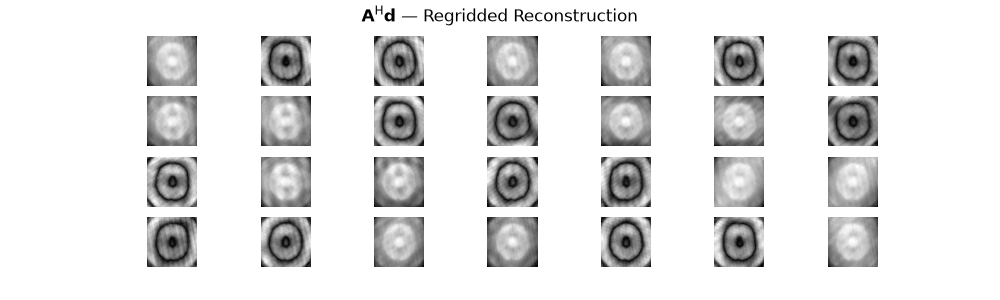

In [13]:
plt.figure(figsize=(10, 3))
plt.suptitle(f"$\\mathbf{{A}}^\\mathrm{{H}} \\mathbf{{d}}$ — Regridded Reconstruction")
for i in range(N_readout_effective):
    plt.subplot(4, N_readout_effective // 4, i + 1)
    plt.imshow(torch.abs(AHd_image[:, :, i]).cpu().numpy().T, cmap="gray")
    plt.axis("off")
plt.show()

In [15]:
# CG SENSE reconstruction

Q = A.H @ A

b = AHd
x = torch.zeros(N_x * N_x * N_readout_effective, dtype=torch.complex64).view(torch.float32)

x_recon = conjugate_gradient(Q, b, x, maxiter=30)

x_recon_image = x_recon.view(torch.complex64).reshape((N_x, N_x, N_readout_effective))

100%|██████████| 30/30 [01:04<00:00,  2.14s/it]


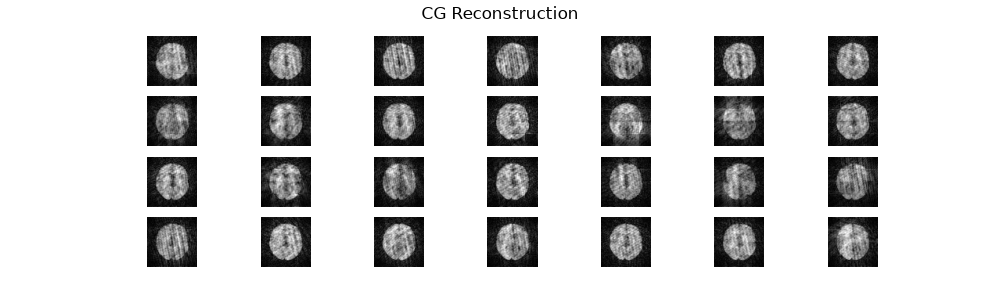

In [16]:
plt.figure(figsize=(10, 3))
plt.suptitle(f"CG Reconstruction")
for i in range(N_readout_effective):
    plt.subplot(4, N_readout_effective // 4, i + 1)
    plt.imshow(torch.abs(x_recon_image[:, :, i]).cpu().numpy().T, cmap="gray")
    plt.axis("off")
plt.show()